In [1]:
import torch, os
print('PyTorch :', torch.__version__)
print('CUDA    :', torch.cuda.is_available())
print('GPUs    :', torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f'  GPU {i} :', torch.cuda.get_device_name(i))

PyTorch : 2.10.0+cu128
CUDA    : True
GPUs    : 2
  GPU 0 : Tesla T4
  GPU 1 : Tesla T4


In [2]:
import torch, os

SICAP_IMG = '/kaggle/input/datasets/rayeneeeeeeeeee/sicapv2/SICAPv2_Kaggle/Train/Images'
SICAP_MSK = '/kaggle/input/datasets/rayeneeeeeeeeee/sicapv2/SICAPv2_Kaggle/Train/Masks'
OUT_DIR   = '/kaggle/working'
CKPT_PATH = os.path.join(OUT_DIR, 'protonet_sicap_best.pt')

N_WAY   = 2
K_SHOT  = 5
Q_QUERY = 10
META_BS = 4

LR         = 0.001
NUM_EPOCHS = 20

TRAIN_EPS = 400
VAL_EPS   = 100
TEST_EPS  = 100

IMG_SIZE = 128
DEVICE   = 'cuda' if torch.cuda.is_available() else 'cpu'

print('Device   :', DEVICE)
print('GPUs     :', torch.cuda.device_count())
print(f'FSL      : {N_WAY}-way {K_SHOT}-shot, {Q_QUERY} queries')
print(f'LR       : {LR}')
print('No inner loop — classification by distance to prototypes')

Device   : cuda
GPUs     : 2
FSL      : 2-way 5-shot, 10 queries
LR       : 0.001
No inner loop — classification by distance to prototypes


In [ ]:
import os, random
import numpy as np
from PIL import Image

# ── Derive binary labels from pixel masks ─────────────────────────────────────
# A patch is "cancer" if more than 30% of its mask is tumour (value 100),
# "benign" if it is mostly background (value 0) with < 10% tumour.
# Benign patches are capped at 2,000 to limit class imbalance.
assert os.path.isdir(SICAP_IMG), f'Not found: {SICAP_IMG}'
assert os.path.isdir(SICAP_MSK), f'Not found: {SICAP_MSK}'


def get_sicap_binary(img_dir, mask_dir,
                     cancer_thresh=0.30,
                     max_benign=2000, seed=42):
    random.seed(seed)
    cancer, benign = [], []
    for fname in sorted(os.listdir(img_dir)):
        mpath = os.path.join(mask_dir, fname)
        ipath = os.path.join(img_dir,  fname)
        if not os.path.exists(mpath): continue
        mask  = np.array(Image.open(mpath))
        c_pct = (mask == 100).sum() / mask.size
        b_pct = (mask == 0).sum()   / mask.size
        if c_pct > cancer_thresh:
            cancer.append(ipath)
        elif b_pct > 0.5 and c_pct < 0.10:
            benign.append(ipath)
    random.shuffle(benign)
    benign = benign[:max_benign]
    return benign, cancer


benign_paths, cancer_paths = get_sicap_binary(SICAP_IMG, SICAP_MSK)

print(f'Benign : {len(benign_paths):,}')
print(f'Cancer : {len(cancer_paths):,}')
assert len(benign_paths) >= K_SHOT + Q_QUERY, 'Too few benign images'
assert len(cancer_paths) >= K_SHOT + Q_QUERY, 'Too few cancer images'

class_to_files = {'benign': benign_paths, 'cancer': cancer_paths}

In [4]:
random.seed(42)

def make_img_dict(class_to_files, fs, fe):
    d = {}
    for c, files in class_to_files.items():
        f = files[:]
        random.shuffle(f)
        d[c] = f[int(fs*len(f)) : int(fe*len(f))]
    return d

train_dict = make_img_dict(class_to_files, 0.00, 0.70)
val_dict   = make_img_dict(class_to_files, 0.70, 0.85)
test_dict  = make_img_dict(class_to_files, 0.85, 1.00)

for name, d in [('Train', train_dict),
                ('Val',   val_dict),
                ('Test',  test_dict)]:
    total = sum(len(v) for v in d.values())
    print(f'{name:5s}: {len(d)} classes, {total:,} images')

Train: 2 classes, 2,305 images
Val  : 2 classes, 494 images
Test : 2 classes, 494 images


In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T


class FSLDataset(Dataset):
    def __init__(self, class_dict, n_way, k_shot, q_query,
                 n_episodes, img_size=128, augment=False):
        super().__init__()
        self.class_dict = class_dict
        self.classes    = list(class_dict.keys())
        self.n_way      = n_way
        self.k_shot     = k_shot
        self.q_query    = q_query
        self.n_episodes = n_episodes

        need  = k_shot + q_query
        short = [c for c, f in class_dict.items() if len(f) < need]
        assert not short, f'Too few images: {short}'

        aug = [
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.ColorJitter(0.2, 0.2, 0.2, 0.05),
        ] if augment else []

        self.transform = T.Compose(aug + [
            T.Resize([img_size, img_size]),
            T.ToTensor(),
            T.Normalize([0.485, 0.456, 0.406],
                        [0.229, 0.224, 0.225]),
        ])

    def __len__(self): return self.n_episodes

    def _load(self, path):
        return self.transform(Image.open(path).convert('RGB'))

    def __getitem__(self, _):
        chosen = random.sample(self.classes, self.n_way)
        sup_imgs, qry_imgs = [], []
        sup_tgts, qry_tgts = [], []
        for label, cls in enumerate(chosen):
            paths = random.sample(
                self.class_dict[cls],
                self.k_shot + self.q_query)
            for p in paths[:self.k_shot]:
                sup_imgs.append(self._load(p))
                sup_tgts.append(label)
            for p in paths[self.k_shot:]:
                qry_imgs.append(self._load(p))
                qry_tgts.append(label)
        return (torch.stack(sup_imgs),
                torch.stack(qry_imgs),
                torch.LongTensor(sup_tgts),
                torch.LongTensor(qry_tgts))


def collate_episodes(batch): return batch

train_ds = FSLDataset(train_dict, N_WAY, K_SHOT, Q_QUERY,
                      TRAIN_EPS, IMG_SIZE, augment=True)
val_ds   = FSLDataset(val_dict,   N_WAY, K_SHOT, Q_QUERY,
                      VAL_EPS,   IMG_SIZE)
test_ds  = FSLDataset(test_dict,  N_WAY, K_SHOT, Q_QUERY,
                      TEST_EPS,  IMG_SIZE)

train_dl = DataLoader(train_ds, META_BS, shuffle=True,
                      num_workers=2, collate_fn=collate_episodes)
val_dl   = DataLoader(val_ds,   META_BS, shuffle=False,
                      num_workers=2, collate_fn=collate_episodes)
test_dl  = DataLoader(test_ds,  META_BS, shuffle=False,
                      num_workers=2, collate_fn=collate_episodes)

print(f'Train : {len(train_dl)} batches  ({TRAIN_EPS} episodes)')
print(f'Val   : {len(val_dl)} batches  ({VAL_EPS} episodes)')
print(f'Test  : {len(test_dl)} batches  ({TEST_EPS} episodes)')


In [ ]:
import torch.nn as nn
import torchvision.models as models


class ProtoNet(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT)

        self.frozen = nn.Sequential(
            backbone.conv1, backbone.bn1,
            backbone.relu, backbone.maxpool,
            backbone.layer1, backbone.layer2,
            backbone.layer3,
        )
        for p in self.frozen.parameters():
            p.requires_grad = False

        self.encoder = nn.Sequential(
            backbone.layer4,
            backbone.avgpool,
            nn.Flatten(),
        )

    def forward(self, x):
        with torch.no_grad():
            x = self.frozen(x)
        x = self.encoder(x)                         # (B, 512)
        return nn.functional.normalize(x, dim=1)    # unit-norm embedding


model = ProtoNet().to(DEVICE)

frozen_p    = sum(p.numel() for p in model.frozen.parameters())
trainable_p = sum(p.numel() for p in model.parameters()
                  if p.requires_grad)
print(f'Frozen params    : {frozen_p:,}')
print(f'Trainable params : {trainable_p:,}')

dummy = torch.zeros(4, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
embed = model(dummy)
print(f'Embedding shape  : {tuple(embed.shape)}')

In [7]:
def euclidean_dist(a, b):
    
    n = a.size(0); m = b.size(0)
    a = a.unsqueeze(1).expand(n, m, -1)
    b = b.unsqueeze(0).expand(n, m, -1)
    return torch.pow(a - b, 2).sum(2)


def proto_episode(encoder, support, query,
                  s_tgt, q_tgt):
   
    sup_emb    = encoder(support)
    prototypes = sup_emb.view(N_WAY, K_SHOT, -1).mean(1)
    qry_emb    = encoder(query)
    dists      = euclidean_dist(qry_emb, prototypes)
    logits     = -dists
    loss       = nn.functional.cross_entropy(logits, q_tgt)
    acc        = (logits.argmax(1) == q_tgt
                  ).float().mean().item() * 100
    return loss, acc


optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad,
           model.parameters()), lr=LR)
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=10, gamma=0.5)

print('ProtoNet helpers defined')
print(f'Optimizer : Adam lr={LR}')
print(f'Scheduler : StepLR step=10 gamma=0.5')

ProtoNet helpers defined
Optimizer : Adam lr=0.001
Scheduler : StepLR step=10 gamma=0.5


In [8]:
import time, gc

best_val_acc = 0.0
no_improve   = 0
patience     = 6
history = {
    'train_acc': [], 'val_acc': [],
    'train_loss': [], 'val_loss': [],
}

print(f'ProtoNet training on SICAPv2 — {NUM_EPOCHS} epochs')
print(f'{N_WAY}-way {K_SHOT}-shot | no inner loop')
print(f'Early stop patience={patience}')
print('=' * 60)

for epoch in range(1, NUM_EPOCHS + 1):
   
    model.train()
    ep_accs, ep_losses = [], []
    t0 = time.time()

    for batch in train_dl:
        optimizer.zero_grad(set_to_none=True)
        batch_loss = torch.tensor(0.0, device=DEVICE)
        batch_accs = []

        for (sup, qry, s_tgt, q_tgt) in batch:
            sup   = sup.to(DEVICE)
            qry   = qry.to(DEVICE)
            s_tgt = s_tgt.to(DEVICE)
            q_tgt = q_tgt.to(DEVICE)
            loss, acc = proto_episode(
                model, sup, qry, s_tgt, q_tgt)
            batch_loss = batch_loss + loss
            batch_accs.append(acc)

        batch_loss = batch_loss / len(batch)
        batch_loss.backward()
        nn.utils.clip_grad_norm_(
            model.parameters(), 10.0)
        optimizer.step()

        ep_losses.append(batch_loss.item())
        ep_accs.extend(batch_accs)
    model.eval()
    val_accs, val_losses = [], []
    for batch in val_dl:
        for (sup, qry, s_tgt, q_tgt) in batch:
            sup   = sup.to(DEVICE)
            qry   = qry.to(DEVICE)
            s_tgt = s_tgt.to(DEVICE)
            q_tgt = q_tgt.to(DEVICE)
            with torch.no_grad():
                loss, acc = proto_episode(
                    model, sup, qry, s_tgt, q_tgt)
            val_accs.append(acc)
            val_losses.append(loss.item())

    scheduler.step()

    tr_acc  = sum(ep_accs)    / len(ep_accs)
    tr_loss = sum(ep_losses)  / len(ep_losses)
    vl_acc  = sum(val_accs)   / len(val_accs)
    vl_loss = sum(val_losses) / len(val_losses)

    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)

    elapsed = time.time() - t0
    print(f'Ep {epoch:02d}/{NUM_EPOCHS}  '
          f'Train {tr_acc:5.2f}% loss={tr_loss:.4f}  '
          f'Val {vl_acc:5.2f}% loss={vl_loss:.4f}  '
          f'({elapsed:.0f}s)')

    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        no_improve   = 0
        torch.save(model.state_dict(), CKPT_PATH)
        print(f'  -> Saved (best val={best_val_acc:.2f}%)')
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f'  Early stop at epoch {epoch}')
            break

    torch.cuda.empty_cache()
    gc.collect()

print('=' * 60)
print(f'Training done. Best val: {best_val_acc:.2f}%')

ProtoNet training on SICAPv2 — 20 epochs
2-way 5-shot | no inner loop
Early stop patience=6
Ep 01/20  Train 90.50% loss=0.3333  Val 91.05% loss=0.3182  (192s)
  -> Saved (best val=91.05%)
Ep 02/20  Train 94.26% loss=0.2600  Val 93.35% loss=0.2761  (186s)
  -> Saved (best val=93.35%)
Ep 03/20  Train 95.35% loss=0.2353  Val 93.55% loss=0.2647  (183s)
  -> Saved (best val=93.55%)
Ep 04/20  Train 96.13% loss=0.2215  Val 96.15% loss=0.2232  (185s)
  -> Saved (best val=96.15%)
Ep 05/20  Train 96.94% loss=0.2023  Val 95.25% loss=0.2361  (184s)
Ep 06/20  Train 97.51% loss=0.1893  Val 93.40% loss=0.2743  (183s)
Ep 07/20  Train 97.51% loss=0.1886  Val 95.75% loss=0.2366  (183s)
Ep 08/20  Train 97.65% loss=0.1856  Val 95.05% loss=0.2435  (184s)
Ep 09/20  Train 98.14% loss=0.1752  Val 96.20% loss=0.2253  (186s)
  -> Saved (best val=96.20%)
Ep 10/20  Train 98.19% loss=0.1717  Val 95.50% loss=0.2287  (183s)
Ep 11/20  Train 98.69% loss=0.1616  Val 96.25% loss=0.2143  (183s)
  -> Saved (best val=96.25

In [9]:
model.load_state_dict(
    torch.load(CKPT_PATH, map_location=DEVICE))
model.eval()

test_accs, test_losses = [], []
all_preds, all_labels  = [], []

for batch in test_dl:
    for (sup, qry, s_tgt, q_tgt) in batch:
        sup   = sup.to(DEVICE)
        qry   = qry.to(DEVICE)
        s_tgt = s_tgt.to(DEVICE)
        q_tgt = q_tgt.to(DEVICE)
        with torch.no_grad():
            loss, acc = proto_episode(
                model, sup, qry, s_tgt, q_tgt)
            sup_emb    = model(sup)
            prototypes = sup_emb.view(
                N_WAY, K_SHOT, -1).mean(1)
            qry_emb    = model(qry)
            dists      = euclidean_dist(qry_emb, prototypes)
            preds      = (-dists).argmax(1).cpu().numpy()
        test_accs.append(acc)
        test_losses.append(loss.item())
        all_preds.extend(preds)
        all_labels.extend(q_tgt.cpu().numpy())

test_acc  = sum(test_accs)   / len(test_accs)
test_loss = sum(test_losses) / len(test_losses)
baseline  = 100.0 / N_WAY

print(f'\n{"="*50}')
print(f'ProtoNet SICAPv2 — {N_WAY}-way {K_SHOT}-shot')
print(f'{"="*50}')
print(f'Test accuracy   : {test_acc:.2f}%')
print(f'Test loss       : {test_loss:.4f}')
print(f'Random baseline : {baseline:.1f}%')
print(f'Gain over random: +{test_acc - baseline:.2f}%')
print(f'{"="*50}')


ProtoNet SICAPv2 — 2-way 5-shot
Test accuracy   : 95.45%
Test loss       : 0.2235
Random baseline : 50.0%
Gain over random: +45.45%


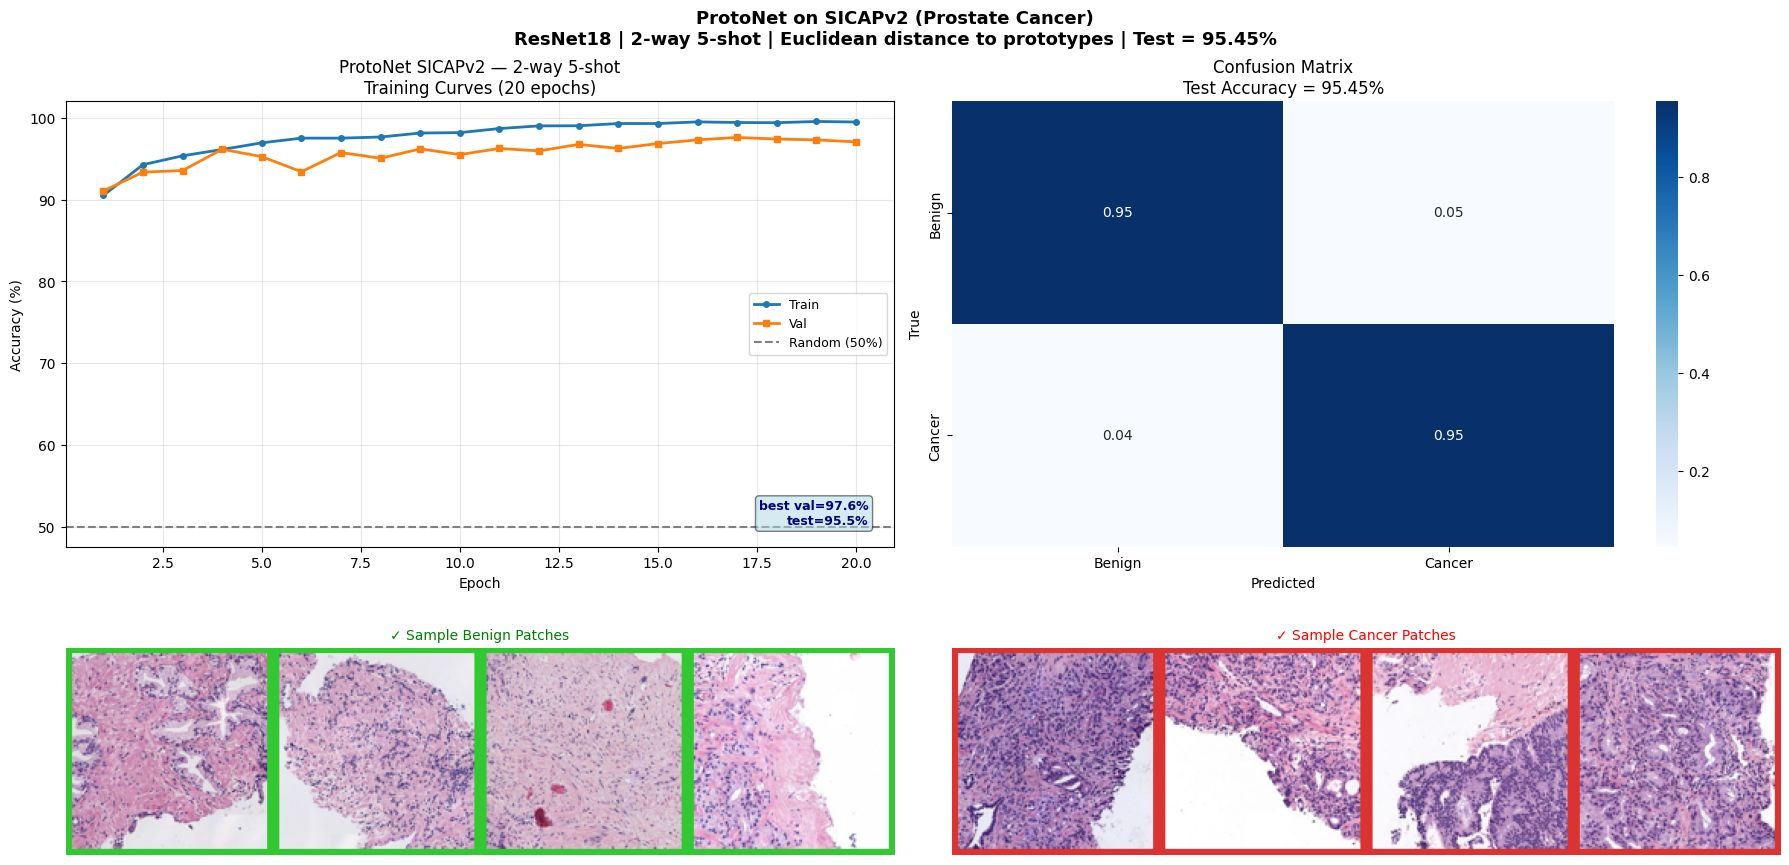

              precision    recall  f1-score   support

      Benign       0.95      0.95      0.95      1000
      Cancer       0.95      0.95      0.95      1000

    accuracy                           0.95      2000
   macro avg       0.95      0.95      0.95      2000
weighted avg       0.95      0.95      0.95      2000

Saved.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import (confusion_matrix,
                              classification_report)
from PIL import Image
import random

fig = plt.figure(figsize=(18, 10))

actual_epochs = len(history['train_acc'])
ep = range(1, actual_epochs + 1)
ax1 = fig.add_subplot(2, 2, 1)
ax1.plot(ep, history['train_acc'], 'o-',
         label='Train', markersize=4, linewidth=2)
ax1.plot(ep, history['val_acc'],   's-',
         label='Val',   markersize=4, linewidth=2)
ax1.axhline(baseline, color='gray', linestyle='--',
            linewidth=1.5,
            label=f'Random ({baseline:.0f}%)')
ax1.set_title(f'ProtoNet SICAPv2 — {N_WAY}-way {K_SHOT}-shot\n'
              f'Training Curves ({actual_epochs} epochs)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy (%)')
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3)
best_v = max(history['val_acc'])
ax1.text(0.97, 0.05,
         f'best val={best_v:.1f}%\ntest={test_acc:.1f}%',
         transform=ax1.transAxes, ha='right',
         fontsize=9, color='navy', fontweight='bold',
         bbox=dict(boxstyle='round',
                   facecolor='lightblue', alpha=0.5))

ax2 = fig.add_subplot(2, 2, 2)
class_names = ['Benign', 'Cancer']
cm   = confusion_matrix(all_labels, all_preds)
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_n, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names, ax=ax2)
ax2.set_title(f'Confusion Matrix\n'
              f'Test Accuracy = {test_acc:.2f}%')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('True')

random.seed(99)

def show_samples(ax, paths, title, border_color, n=4):
    if not paths:
        ax.text(0.5, 0.5, 'No samples',
                ha='center', va='center',
                transform=ax.transAxes, fontsize=10)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
        return
    sampled = random.sample(paths, min(n, len(paths)))
    strip   = []
    for p in sampled:
        img = np.array(
            Image.open(p).convert('RGB')
            .resize((128, 128)))
        bordered = np.ones((136, 136, 3), dtype=np.uint8)
        if border_color == 'green':
            bordered[:, :] = [50, 200, 50]
        else:
            bordered[:, :] = [220, 50, 50]
        bordered[4:132, 4:132] = img
        strip.append(bordered)
    combined = np.concatenate(strip, axis=1)
    ax.imshow(combined)
    ax.set_title(title, fontsize=10,
                 color='green' if border_color == 'green'
                 else 'red')
    ax.axis('off')

ax3 = fig.add_subplot(2, 2, 3)
show_samples(ax3, list(test_dict['benign']),
             '✓ Sample Benign Patches', 'green')

ax4 = fig.add_subplot(2, 2, 4)
show_samples(ax4, list(test_dict['cancer']),
             '✓ Sample Cancer Patches', 'red')

plt.suptitle(
    f'Test = {test_acc:.2f}%',
    fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,
            'protonet_sicap_results.png'), dpi=150)
plt.show()
print(classification_report(
    all_labels, all_preds,
    target_names=class_names))
print('Saved.')